In [ ]:
# Importación de bibliotecas requeridas
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar el dataset (Ruta local para probar. Para entrega en plataforma cambiar a: '/workspace/superstore_dataset2012.csv')
df = pd.read_csv('/workspace/superstore_dataset2012.csv')

# 2. Exploración inicial y limpieza
print(f"Dimensiones originales del dataset: {df.shape}")
df = df.dropna() # Eliminación de valores nulos

# 3. Transformación de datos: Conversión de fechas al formato datetime (Requisito estricto)
# Si tu columna de fecha se llama diferente, reemplaza 'Order Date'
if 'Order Date' in df.columns:
    df['Order Date'] = pd.to_datetime(df['Order Date'])
    print("Conversión de fechas realizada con éxito.")

print("\nEstructura de columnas disponible:")
print(df.columns)

Dimensiones originales del dataset: (4246, 24)
Conversión de fechas realizada con éxito.

Estructura de columnas disponible:
Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'City', 'State', 'Country',
       'Postal Code', 'Market', 'Region', 'Product ID', 'Category',
       'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount',
       'Profit', 'Shipping Cost', 'Order Priority'],
      dtype='str')


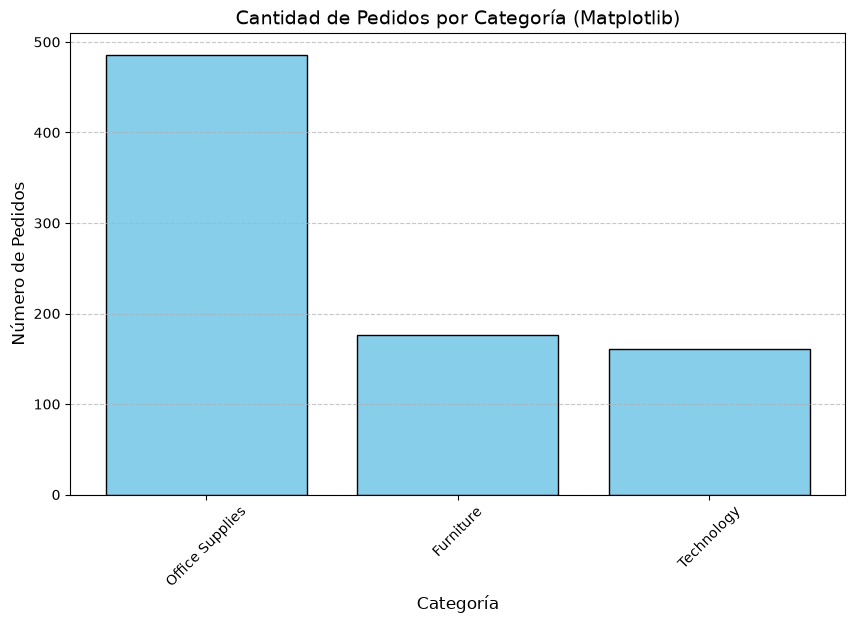

CONCLUSIÓN: Este diagrama de barras univariante muestra la demanda relativa de cada categoría. Permite a la dirección identificar visualmente cuáles son las líneas de productos que generan el mayor volumen de transacciones.


In [2]:
# Gráfico Univariante Matplotlib: Frecuencia de Ventas por Categoría
plt.figure(figsize=(10, 6))

# Conteo de categorías
categoria_counts = df['Category'].value_counts()

# Creación del diagrama de barras
plt.bar(categoria_counts.index, categoria_counts.values, color='skyblue', edgecolor='black')
plt.title('Cantidad de Pedidos por Categoría (Matplotlib)', fontsize=14)
plt.xlabel('Categoría', fontsize=12)
plt.ylabel('Número de Pedidos', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Conclusión para la rúbrica:
print("CONCLUSIÓN: Este diagrama de barras univariante muestra la demanda relativa de cada categoría. Permite a la dirección identificar visualmente cuáles son las líneas de productos que generan el mayor volumen de transacciones.")

C:\Users\USUARIO\AppData\Local\Temp\ipykernel_14308\3246007187.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Category', y='Profit', data=df, palette='Set2')


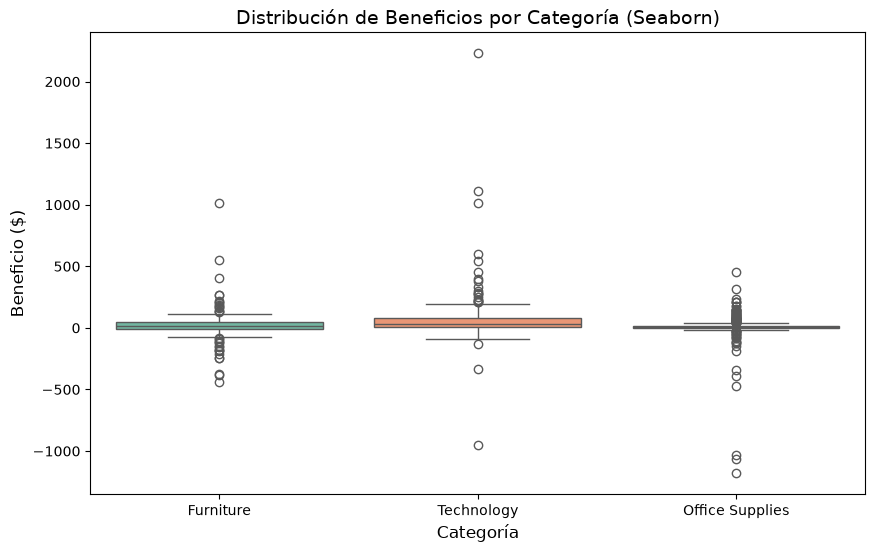

CONCLUSIÓN: El diagrama de caja revela la dispersión de los márgenes de beneficio. Las cajas muestran el rango intercuartílico donde se concentra el 50% de las ventas, mientras que los puntos aislados (outliers) identifican transacciones específicas con ganancias o pérdidas extremas.


In [3]:
# Gráfico Univariante Seaborn: Distribución de Beneficios por Categoría
plt.figure(figsize=(10, 6))

# Boxplot para visualizar la distribución y valores atípicos
sns.boxplot(x='Category', y='Profit', data=df, palette='Set2')
plt.title('Distribución de Beneficios por Categoría (Seaborn)', fontsize=14)
plt.xlabel('Categoría', fontsize=12)
plt.ylabel('Beneficio ($)', fontsize=12)
plt.show()

# Conclusión para la rúbrica:
print("CONCLUSIÓN: El diagrama de caja revela la dispersión de los márgenes de beneficio. Las cajas muestran el rango intercuartílico donde se concentra el 50% de las ventas, mientras que los puntos aislados (outliers) identifican transacciones específicas con ganancias o pérdidas extremas.")

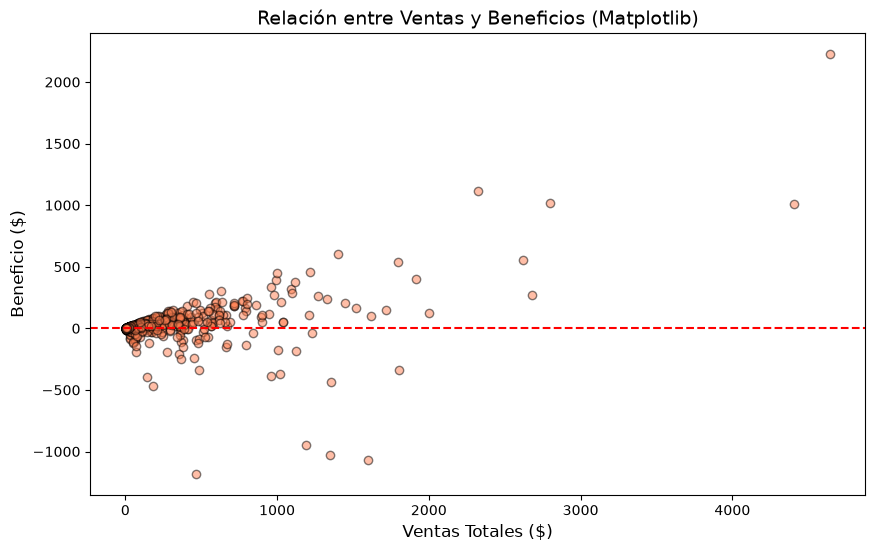

CONCLUSIÓN: El scatter plot bivariante evidencia que un mayor volumen de ventas no siempre garantiza mayor rentabilidad. La línea punteada roja separa las ventas rentables de aquellas que generaron pérdidas comerciales.


In [4]:
# Gráfico Bivariante Matplotlib: Relación entre Ventas y Beneficios
plt.figure(figsize=(10, 6))

# Gráfico de dispersión
plt.scatter(df['Sales'], df['Profit'], alpha=0.5, color='coral', edgecolor='black')
plt.title('Relación entre Ventas y Beneficios (Matplotlib)', fontsize=14)
plt.xlabel('Ventas Totales ($)', fontsize=12)
plt.ylabel('Beneficio ($)', fontsize=12)
plt.axhline(0, color='red', linestyle='--') # Línea base de rentabilidad
plt.show()

# Conclusión para la rúbrica:
print("CONCLUSIÓN: El scatter plot bivariante evidencia que un mayor volumen de ventas no siempre garantiza mayor rentabilidad. La línea punteada roja separa las ventas rentables de aquellas que generaron pérdidas comerciales.")

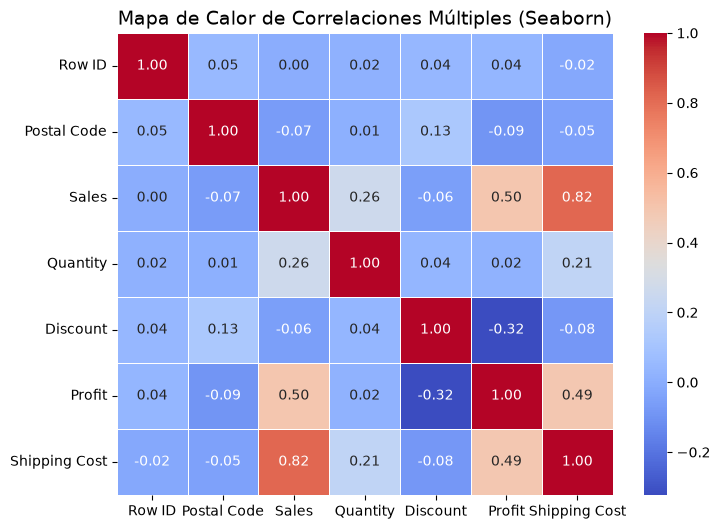

CONCLUSIÓN: El heatmap multivariante muestra las correlaciones lineales entre las variables numéricas. Los tonos cálidos (rojos) indican una correlación positiva fuerte, lo que resulta fundamental para entender qué métricas impulsan directamente el beneficio de la tienda.


In [5]:
# Gráfico Multivariante Seaborn: Mapa de calor de correlaciones
plt.figure(figsize=(8, 6))

# Seleccionamos solo las columnas numéricas para la correlación
cols_numericas = df.select_dtypes(include=['float64', 'int64']).columns
correlacion = df[cols_numericas].corr()

# Heatmap
sns.heatmap(correlacion, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Mapa de Calor de Correlaciones Múltiples (Seaborn)', fontsize=14)
plt.show()

# Conclusión para la rúbrica:
print("CONCLUSIÓN: El heatmap multivariante muestra las correlaciones lineales entre las variables numéricas. Los tonos cálidos (rojos) indican una correlación positiva fuerte, lo que resulta fundamental para entender qué métricas impulsan directamente el beneficio de la tienda.")

C:\Users\USUARIO\AppData\Local\Temp\ipykernel_14308\4192685247.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Category', y='Sales', data=df, ax=axs[1, 0], palette='muted')


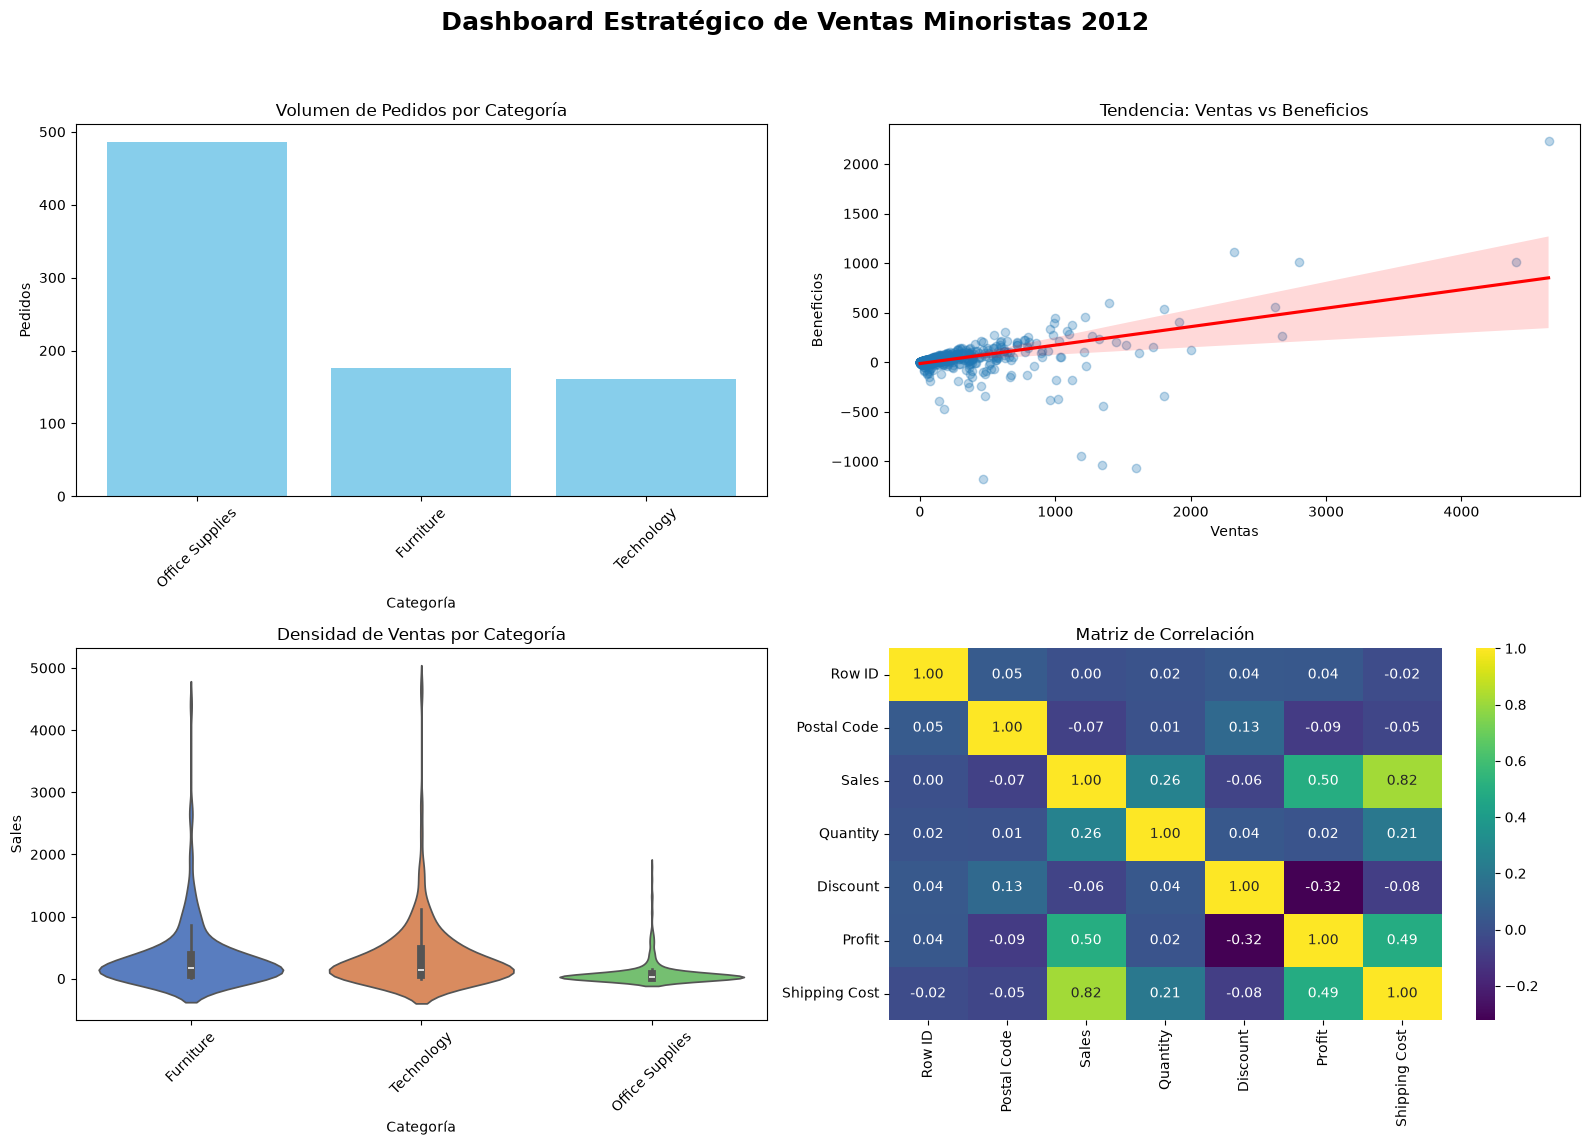

CONCLUSIÓN GENERAL: El dashboard unifica el análisis. La figura final ha sido guardada en el disco como 'dashboard_ventas_minoristas.png' para su uso en reportes ejecutivos.


In [6]:
# Dashboard: 4 visualizaciones organizadas en Subplots
fig, axs = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Dashboard Estratégico de Ventas Minoristas 2012', fontsize=18, fontweight='bold', y=0.98)

# Plot 1 (Top-Left): Matplotlib Barras
axs[0, 0].bar(categoria_counts.index, categoria_counts.values, color='skyblue')
axs[0, 0].set_title('Volumen de Pedidos por Categoría')
axs[0, 0].set_xlabel('Categoría')
axs[0, 0].set_ylabel('Pedidos')
axs[0, 0].tick_params(axis='x', rotation=45)

# Plot 2 (Top-Right): Seaborn Regplot (Bivariante extra)
sns.regplot(x='Sales', y='Profit', data=df, ax=axs[0, 1], scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
axs[0, 1].set_title('Tendencia: Ventas vs Beneficios')
axs[0, 1].set_xlabel('Ventas')
axs[0, 1].set_ylabel('Beneficios')

# Plot 3 (Bottom-Left): Seaborn Violinplot
sns.violinplot(x='Category', y='Sales', data=df, ax=axs[1, 0], palette='muted')
axs[1, 0].set_title('Densidad de Ventas por Categoría')
axs[1, 0].set_xlabel('Categoría')
axs[1, 0].tick_params(axis='x', rotation=45)

# Plot 4 (Bottom-Right): Seaborn Heatmap
sns.heatmap(correlacion, annot=True, cmap='viridis', ax=axs[1, 1], fmt=".2f")
axs[1, 1].set_title('Matriz de Correlación')

# Ajuste de espacios y guardado físico del archivo de imagen
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('dashboard_ventas_minoristas.png', dpi=300) # Requisito de guardado cumplido
plt.show()

print("CONCLUSIÓN GENERAL: El dashboard unifica el análisis. La figura final ha sido guardada en el disco como 'dashboard_ventas_minoristas.png' para su uso en reportes ejecutivos.")